# 05 · Q1 controls: most of what model A reads comes from the states, not from the actions

**What this notebook shows.** All 100 ants in a run share one eps, so the colony's pheromone trails and where ants tend to be already depend on eps. A model could then "read eps" from *places* rather than from *behaviour*. Two control models test this. They are identical to model A except for the input:
- **C, states only**: no previous actions. Behaviour is only visible indirectly, through how the state changes from step to step.
- **D, states only, time shuffled**: each ant's steps are put in random order. This keeps where the ant spent its time and destroys how it moved. Anything D can read is leaking from places.

**Results (recorded run on the full dataset, val windows).**

| model | eps error (eps <= 0.7) | slope | gap, history 64-127 |
|---|---|---|---|
| A, states + actions | 0.078 | 0.76 | 0.0234 |
| C, states only | 0.069 | 0.72 | 0.0267 |
| D, states shuffled | 0.099 | 0.75 | 0.0307 |

All three read eps at history 0 (A 0.48 to 0.72, C 0.52 to 0.68, D 0.52 to 0.70 from eps 0.1 to 1.0).

**Conclusion.** The shuffled control D, which cannot see behaviour at all, reads eps nearly as well as A. Time order helps somewhat (C beats D), but explicit actions add nothing over states alone (A is no better than C). So in this dataset most of model A's eps reading is **leak through the states**, not inference from the ant's own actions. Any strong claim about "inferring a hidden parameter from behaviour" needs this leak removed (for example a different eps per ant within one colony).

In [3]:
# Shared plumbing (paths, rule, models, plotting) lives in ant_common.py next to this notebook.
from ant_common import *

setup_plots()
seed_everything(0)
print("device:", DEVICE, "| quick mode:", QUICK)
print("data:  ", DATA_DIR)
print("output:", OUT_DIR)

device: cuda | quick mode: False
data:   /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/dataset_20261025_104552_105991
output: /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/eps_models_v2


## 1. Model A's predictions on the same validation windows

In [4]:
model_A = load_seq_model("A")
val_runs = load_split("val")
preds = {"A states+actions": collect_seq(model_A, build_sequences(val_runs, with_actions=True))}

## 2. Train the two controls

In [5]:
CONTROLS = {
    "C states only":           dict(with_actions=False),
    "D states only, shuffled": dict(with_actions=False, shuffle=True),
}
for name, opts in CONTROLS.items():
    print(f"== {name}")
    seed_everything(0)
    train = build_sequences(load_split("train"), **opts)
    model = AntGPT(d_in=19).to(DEVICE)
    train_seq_model(model, train)
    del train
    save_seq_model(model, name.split()[0], d_in=19)
    preds[name] = collect_seq(model, build_sequences(val_runs, **opts))

# A and C see exactly the same windows (D's windows are shuffled by design)
assert np.array_equal(preds["C states only"][1], preds["A states+actions"][1])
print("A and C use identical validation windows")

== C states only
   epoch  1: loss 1.2994   (10 s)
   epoch  2: loss 1.2289   (10 s)
   epoch  3: loss 1.2088   (9 s)
   epoch  4: loss 1.1980   (10 s)
   epoch  5: loss 1.1926   (11 s)
   epoch  6: loss 1.1891   (8 s)
   epoch  7: loss 1.1866   (8 s)
   epoch  8: loss 1.1845   (8 s)
   epoch  9: loss 1.1828   (8 s)
   epoch 10: loss 1.1814   (8 s)
   epoch 11: loss 1.1802   (8 s)
   epoch 12: loss 1.1789   (8 s)
   epoch 13: loss 1.1782   (8 s)
   epoch 14: loss 1.1770   (8 s)
   epoch 15: loss 1.1763   (8 s)
   epoch 16: loss 1.1755   (8 s)
   epoch 17: loss 1.1748   (8 s)
   epoch 18: loss 1.1740   (8 s)
   epoch 19: loss 1.1733   (8 s)
   epoch 20: loss 1.1727   (8 s)
== D states only, shuffled
   epoch  1: loss 1.3070   (8 s)
   epoch  2: loss 1.2277   (8 s)
   epoch  3: loss 1.2044   (8 s)
   epoch  4: loss 1.1954   (8 s)
   epoch  5: loss 1.1908   (8 s)
   epoch  6: loss 1.1876   (8 s)
   epoch  7: loss 1.1849   (8 s)
   epoch  8: loss 1.1831   (8 s)
   epoch  9: loss 1.1814   (

## 3. Compare A, C and D

In [6]:
results = {name: summarize_seq_model(*p) for name, p in preds.items()}
print("===== headline scores =====")
print(pd.DataFrame({name: r[2] for name, r in results.items()}).round(4))
print("\n===== implied eps with NO history (one state) =====")
print(pd.DataFrame({name: r[1]["0"] for name, r in results.items()}).round(3))
print("\n===== implied eps after 64-127 steps =====")
print(pd.DataFrame({name: r[1]["64-127"] for name, r in results.items()}).round(3))

===== headline scores =====
                                   A states+actions  C states only  \
gap, no-history ideal                        0.0459         0.0459   
gap, history 0                               0.0472         0.0563   
gap, history 64-127                          0.0213         0.0245   
rule agreement, 64-127 (eps<=0.7)            0.9768         0.9739   
eps error, all eps                           0.0720         0.0711   
eps error, eps<=0.7                          0.0794         0.0704   
eps slope (want 1)                           0.7705         0.7337   
eps intercept (want 0)                       0.1672         0.1738   

                                   D states only, shuffled  
gap, no-history ideal                               0.0474  
gap, history 0                                      0.0638  
gap, history 64-127                                 0.0290  
rule agreement, 64-127 (eps<=0.7)                   0.9705  
eps error, all eps                  

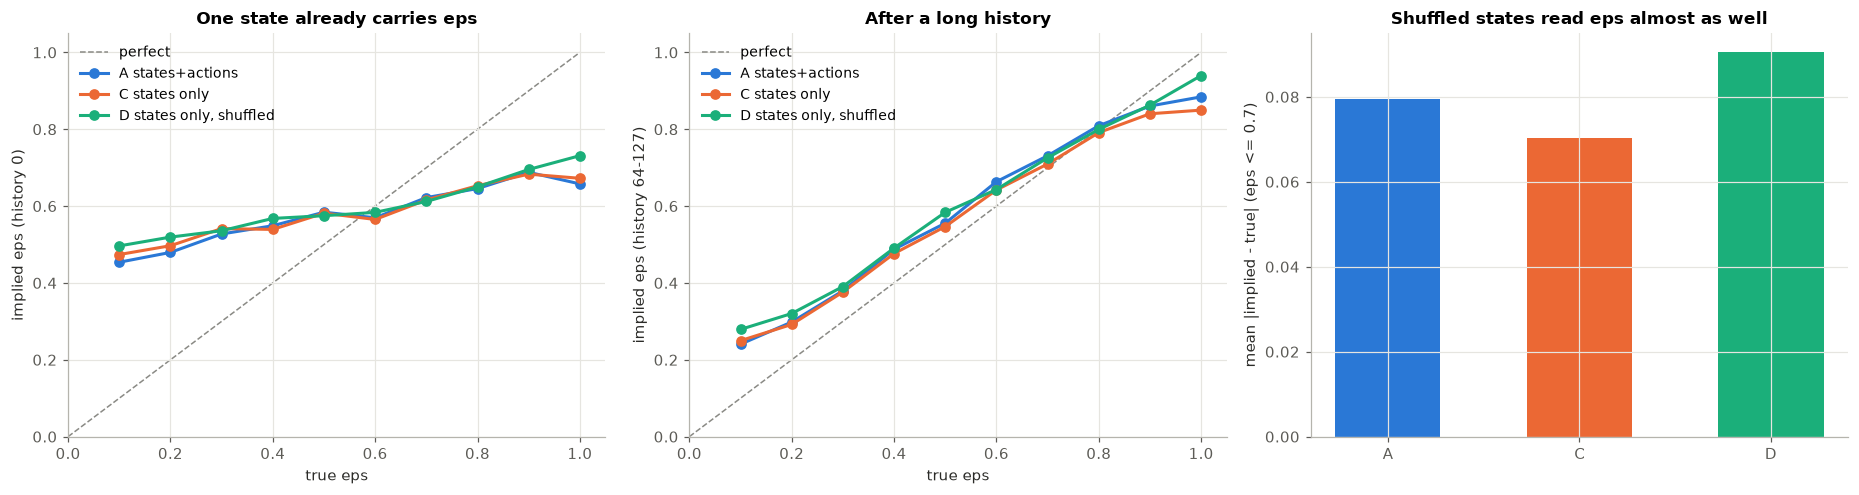

In [7]:
colors = {"A states+actions": C["blue"], "C states only": C["orange"], "D states only, shuffled": C["aqua"]}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, col, title in [(axes[0], "0", "One state already carries eps"),
                       (axes[1], "64-127", "After a long history")]:
    diagonal(ax)
    for name, (_, by_eps, _) in results.items():
        ax.plot(by_eps.index, by_eps[col], "-o", color=colors[name], label=name)
    ax.set(xlabel="true eps", ylabel=f"implied eps (history {col})", title=title)
    ax.legend()

ax = axes[2]
names = list(results)
x = np.arange(len(names))
ax.bar(x, [results[n][2]["eps error, eps<=0.7"] for n in names], width=0.55,
       color=[colors[n] for n in names])
ax.set_xticks(x, [n.split()[0] for n in names])
ax.set(ylabel="mean |implied - true| (eps <= 0.7)", title="Shuffled states read eps almost as well")
plt.tight_layout()
plt.show()

**Analysis.** Recorded headline scores:

| | A states+actions | C states only | D shuffled |
|---|---|---|---|
| gap, history 0 | 0.0558 | 0.0620 | 0.0658 |
| gap, history 64-127 | 0.0234 | 0.0267 | 0.0307 |
| eps error, eps <= 0.7 | 0.0780 | 0.0691 | 0.0990 |
| eps slope / intercept | 0.76 / 0.17 | 0.72 / 0.18 | 0.75 / 0.20 |

- **Left panel**: with zero history all three models already give higher eps to higher-eps colonies. The state alone carries eps.
- **Middle and right panels**: D never sees how an ant moves, yet ends up with an eps error only about 0.02 worse than A. Most of the signal is in *which states an ant visits* (random colonies build fewer trails, so ants see less smell and more "no signal").
- **A vs C**: adding the previous action does not help. Whatever A uses, C can get from states alone.

This does not mean behaviour carries no eps information (C beats D, and model B in notebook 06 reads eps from deviations). It means this dataset does not *isolate* it: eps is shared by the whole colony, so the environment encodes it too.